# High Cardinality Reduction

### <i> Using Agglomerative Clustering


<br>
<br>



<br>

 Agglomerative clustering can be used in a way such that you reduce the high-cardinality of a single column into the hierarchial clusters from the variance of its many other features. This works well when datasets have minimal overlap and generally have nominal columns which have a SIGNIFICANT amount of unique values that some other high cardinality methods can't necessarily effectively handle. Agglomerative clustering is typically not the first-choice for handling high-cardinality, and often times doesn't measure up to, for instance, `PCA`. But in some cases, it does perform better!


<br>
<br>


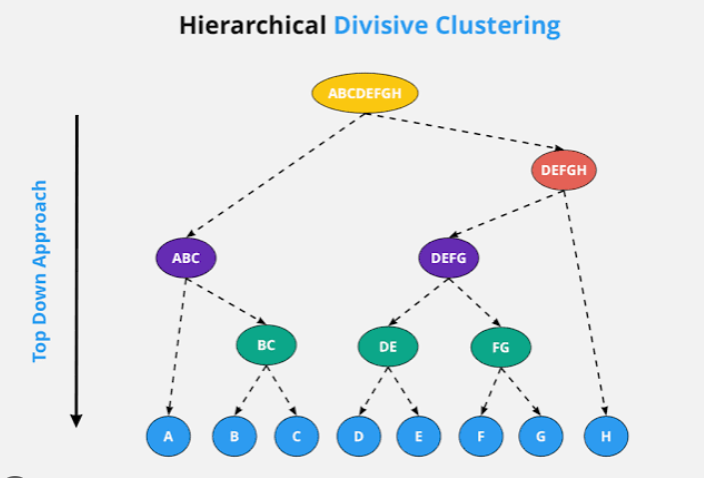

[Source](https://dataaspirant.com/hierarchical-clustering-algorithm/)

<br>
<br>


</strong>



---

### Dataset


In [2]:
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

# This is a dataset I meticulously cleaned that uses crime data.
# It contains only 500 rows of aggregated data at this point, just
# for this purpose.
df = pd.read_csv("../datasets/retail.csv")
df

# Notice how we have 3,922 different products here. 

,StockCode,avg_price,total_quantity,avg_quantity,transaction_count,total_revenue,unique_customers
0,10002,1.086620,860,12.112676,71,759.890000,41
1,10002,1.098527,857,12.286419,72,747.554777,42
2,10002,1.097970,875,11.932494,71,755.962828,42
3,10002,1.092873,877,12.085260,70,761.549137,40
4,10080,0.410909,303,13.772727,22,119.090000,20
...,...,...,...,...,...,...,...
15683,gift_0001_50,42.249694,4,0.988470,4,170.795552,1
15684,m,2.550000,1,1.000000,1,2.550000,1
15685,m,2.576673,1,0.984965,1,2.509821,1
15686,m,2.501526,1,0.997594,1,2.533757,1


In [3]:
df["StockCode"].nunique()

3922

### <i> Problem 

Notice that the stock-code in our groupby function has<strong style='color:red'> multiple thousands of individual product identifiers</strong> . 

You could drop this column but there could be some missing variance and connections in those identifiers which could be useful for the model. 


<br>

Since this is a `nominal` column with high-cardinality, we need to condense the amount of unique values or we'll have 3,921 new columns on our hands.

So let's use agglomerative clustering to mitigate the high-cardinality into a specific amount of clusters.

<br>
<br>

---

### Using agglomerative clustering





In [ ]:
X = df.drop(["avg_price", "StockCode"], axis=1)
y = df["avg_price"]

# Agglo clustering and fitting
model = AgglomerativeClustering(n_clusters=5,linkage="ward")
clusters = model.fit_predict(X)

# Creating a new column that shows the cluster
df["cluster"] = clusters


# Setting up metrics -- Silhouette and ARI
silhouette = silhouette_score(X,clusters)
ari_score = adjusted_rand_score(y, clusters)


# Sillhouette score works for both REGRESSION and CLASSIFICATION
# Range : 0-1 ,  The closer to 1 the better 
print(f"Silhouette Score: {silhouette:.4f}")

# ARI score is only useful for classification -- NOT REGRESSING
# Range : 0-1 ,  The closer to 1 the better
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print("")
print("")

df

# Like mentioned above, ARI is 0.00 and that is normal, this is regression.

Silhouette Score: 0.6719
Adjusted Rand Index (ARI): 0.0000




,StockCode,avg_price,total_quantity,avg_quantity,transaction_count,total_revenue,unique_customers,cluster
0,10002,1.086620,860,12.112676,71,759.890000,41,4
1,10002,1.098527,857,12.286419,72,747.554777,42,4
2,10002,1.097970,875,11.932494,71,755.962828,42,4
3,10002,1.092873,877,12.085260,70,761.549137,40,4
4,10080,0.410909,303,13.772727,22,119.090000,20,4
...,...,...,...,...,...,...,...,...
15683,gift_0001_50,42.249694,4,0.988470,4,170.795552,1,4
15684,m,2.550000,1,1.000000,1,2.550000,1,4
15685,m,2.576673,1,0.984965,1,2.509821,1,4
15686,m,2.501526,1,0.997594,1,2.533757,1,4


<Axes: xlabel='transaction_count', ylabel='unique_customers'>

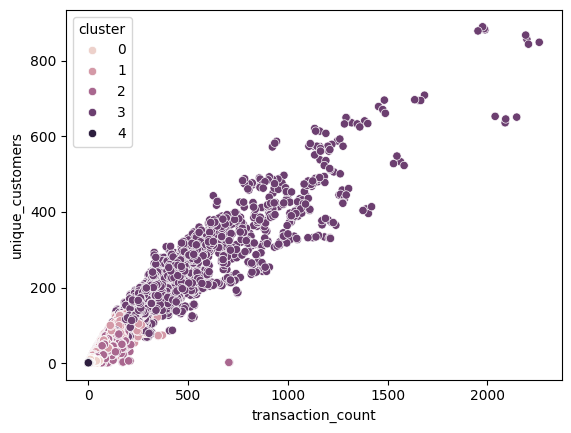

In [8]:
# Here is a neat visual to show how it clustered the values. (Feel free to make more 
# scatterplots with all sorts of feature combinations!)
sns.scatterplot(df, x="transaction_count", y="unique_customers", hue="cluster")

<i> Great, Now we have a `cluster` column, and we can simply drop the `stock_code` altogether.

Now, you might be asking:

"You didn't base the agglomerative clustering on the `StockCode` specifically. So how can you say you even extracted something meaningful from the stock code?"

Let me show you some evidence:




### <i> Comparing Model Performance 

Here I used AI to make a quick little comparitor to show you that it does retrieve some information from the `StockCode` column!

In [6]:
# I used AI here to make a quick XGBoost regressor model trainer and compare the
# performance between using clusters and without clusters.

import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def compare_cluster_models(df):

    y = df["avg_price"]

    # Model A: Without StockCode or clusters
    X_without = df.drop(
        columns=["StockCode", "avg_price", "cluster"],
        errors="ignore"
    )

    # Model B: Include clusters
    X_with = df.drop(
        columns=["StockCode", "avg_price"],
        errors="ignore"
    )

    # Same train/test split for both experiments
    indices = np.arange(len(df))

    train_idx, test_idx = train_test_split(
        indices,
        test_size=0.2,
        random_state=42
    )

    results = {}

    for name, X in [
        ("Without clusters", X_without),
        ("With clusters", X_with)
    ]:

        model = XGBRegressor(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            random_state=42,
            objective="reg:squarederror",
            n_jobs=-1
        )

        model.fit(
            X.iloc[train_idx],
            y.iloc[train_idx]
        )

        predictions = model.predict(X.iloc[test_idx])

        results[name] = {
            "MAE": mean_absolute_error(
                y.iloc[test_idx], predictions
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y.iloc[test_idx], predictions
            )),
            "R2": r2_score(
                y.iloc[test_idx], predictions
            )
        }

    results_df = pd.DataFrame(results).T

    print(results_df.round(4))

    return results_df


comparison = compare_cluster_models(df)


                     MAE     RMSE      R2
Without clusters  0.7777  15.1781  0.9924
With clusters     0.6264   6.0303  0.9988


<i>

As you can see, there is a SMALL improvement here from using clustering --> meaning that it did extract some useful information from the `StockCode` column 

---



<i>

### Using Agglomerative Clustering Incorrectly

Because seeing is believing...

I will show an example of how  <b>NOT to do it </b> and show you metrics to prove it:

In this case, I made a small function to show you why certain preprocessing methods like `scaling` and `feature transformations` before `agglomerative_clustering` might lead to negative results. 

In [7]:

# Original features
# Original features
X = df.drop(["StockCode", "avg_price", "cluster"], axis=1)

# Target (continuous variable)
y = df["avg_price"]

# Log transformation
X_log = np.log1p(X)

# Standard scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Log transformation + scaling
X_log_scaled = scaler.fit_transform(X_log)


# Easy little function so I don't have to repeat my code.
# It does the clustering in a single line.
def evaluate_clustering(X_input, name):

    model = AgglomerativeClustering(
        n_clusters=5,
        linkage="ward"
    )

    clusters = model.fit_predict(X_input)

    silhouette = silhouette_score(X_input, clusters)

    print(name)
    print("------------")
    print(f"Silhouette Score: {silhouette:.4f}")
    print("")

    return clusters


# Run all four experiments
clusters_original = evaluate_clustering(X, "Original")
clusters_log = evaluate_clustering(X_log, "Log transformed")
clusters_scaled = evaluate_clustering(X_scaled, "Scaled")
clusters_log_scaled = evaluate_clustering(X_log_scaled,"Log + Scaled")

# Store one selected clustering in the dataframe
df["cluster"] = clusters_log_scaled


Original
------------
Silhouette Score: 0.6719

Log transformed
------------
Silhouette Score: 0.2769

Scaled
------------
Silhouette Score: 0.5672

Log + Scaled
------------
Silhouette Score: 0.2742



---

<br>

<i>

#### `Sillhouette` score and `ARI` should not be solely relied upon. 

Because the lower the amount of `n_clusters` higher the silhouette + ARI score. Naturally this tanks your model performance even though your agglo clustering metrics are high.




`n_clusters=4`

In [11]:
X = df.drop(["avg_price", "StockCode"], axis=1)
y = df["avg_price"]

# Agglo clustering and fitting
model = AgglomerativeClustering(n_clusters=4,linkage="ward")
clusters = model.fit_predict(X)

# Creating a new column that shows the cluster
df["cluster"] = clusters


# Setting up metrics -- Silhouette and ARI
silhouette = silhouette_score(X,clusters)
ari_score = adjusted_rand_score(y, clusters)


# Sillhouette score works for both REGRESSION and CLASSIFICATION
# Range : 0-1 ,  The closer to 1 the better 
print(f"Silhouette Score: {silhouette:.4f}")

# ARI score is only useful for classification -- NOT REGRESSING
# Range : 0-1 ,  The closer to 1 the better
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print("")
print("")


Silhouette Score: 0.8544
Adjusted Rand Index (ARI): 0.0000




`n_clusters = 3`

In [12]:
X = df.drop(["avg_price", "StockCode"], axis=1)
y = df["avg_price"]

# Agglo clustering and fitting
model = AgglomerativeClustering(n_clusters=3,linkage="ward")
clusters = model.fit_predict(X)

# Creating a new column that shows the cluster
df["cluster"] = clusters


# Setting up metrics -- Silhouette and ARI
silhouette = silhouette_score(X,clusters)
ari_score = adjusted_rand_score(y, clusters)


# Sillhouette score works for both REGRESSION and CLASSIFICATION
# Range : 0-1 ,  The closer to 1 the better 
print(f"Silhouette Score: {silhouette:.4f}")

# ARI score is only useful for classification -- NOT REGRESSING
# Range : 0-1 ,  The closer to 1 the better
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print("")
print("")


Silhouette Score: 0.8535
Adjusted Rand Index (ARI): 0.0000





<strong style='color:red'> Your best source of truth is running an ML model and seeing an improvement with THOSE metrics </strong>